# 8.1 Interpolación Polinomial de Lagrange y Fenómeno de Runge en JobPath (`IDEA-LG-01`, `LG-02`)

**Alineación con la presentación:** `interpolacion_lagrange.html` (Prof. Juan Carlos González Sánchez · UNIMINUTO Ibagué)  
**Proyecto:** JobPath (`MineriaProtect`) · Extensión de Modelado Numérico CRISP-DM  
**Alcance:** Reconstruye curvas empíricas continuas a partir de hitos tabulados de JobPath mediante polinomios base de Lagrange $L_i(x)$ desde primeros principios (incluyendo forma monómica expandida $c_3 x^3 + c_2 x^2 + c_1 x + c_0$), verifica la delta de Kronecker $L_i(x_j) = \delta_{ij}$ y la partición de la unidad $\sum L_i(x) = 1$, contrasta frente a `scipy.interpolate` y demuestra el **Fenómeno de Runge**, la **mitigación con nodos de Chebyshev-Lobatto** ($0$ violaciones en $[0, 1]$), la **interpolación local por tramos $P_2$**, el **cálculo PCA en vivo (`float64`)** y el **bloqueo de nodos repetidos (`MR-04`)** sobre datos reales.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
for cand in (ROOT, *ROOT.parents):
    if (cand / "data").is_dir() and (cand / "scripts").is_dir():
        ROOT = cand
        break
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.ScriptsCsv.MetodosNumericos.config import default_config
from scripts.ScriptsCsv.MetodosNumericos.lagrange import diagnose_lagrange, inverse_lagrange_eval, lagrange_eval

cfg = default_config(ROOT)
tdir, fdir = cfg.tables_dir, cfg.figures_dir

if not (tdir / "lg01_runge_phenomenon_benchmark.csv").exists():
    from scripts.ScriptsCsv.MetodosNumericos.pipeline import run_all_8_ideas
    run_all_8_ideas(cfg)

## 1. Verificación del Motor con los Ejemplos de la Presentación (Diapositivas 6–13)

Verificamos `lagrange_eval` y `diagnose_lagrange` sobre el ejemplo guiado de **Temperatura de CPU** (`P₂(65) = 66.375`, pesos `[-0.125, 0.75, 0.375]`) y el ejercicio de **Práctica** (`P₂(2) = 11`).

In [2]:
y_cpu, w_cpu, _ = lagrange_eval([20, 50, 80], [45, 58, 76], [65])
d_cpu = diagnose_lagrange([20, 50, 80], [45, 58, 76], name="Ejemplo Temp CPU")
y_pr, w_pr, _ = lagrange_eval([0, 1, 3], [1, 3, 25], [2])
print(f"Temp CPU P2(65) = {y_cpu[0]:.6f} | pesos = {w_cpu[0].round(6)} | suma = {w_cpu[0].sum():.12f}")
print(f"Diagnósticos: Kronecker={d_cpu.kronecker_max_err:.2e}, Unidad={d_cpu.unity_sum_max_err:.2e}, SciPy={d_cpu.scipy_max_abs_diff:.2e}")
print(f"Práctica P2(2)  = {y_pr[0]:.6f} | pesos = {w_pr[0].round(6)}")

Temp CPU P2(65) = 66.375000 | pesos = [-0.125  0.75   0.375] | suma = 1.000000000000
Diagnósticos: Kronecker=0.00e+00, Unidad=2.22e-16, SciPy=8.53e-14
Práctica P2(2)  = 11.000000 | pesos = [-0.333333  1.        0.333333]


## 2. `IDEA-LG-01` — Reconstrucción de la Curva de Supervivencia $S(q)$ y Fenómeno de Runge Empírico

**Propósito:** Usando las `1,643,772` experiencias clasificadas estrictamente cerradas (`~es_vigente`), se construye la curva cúbica de Lagrange $P_3(q)$ con 4 hitos ($q \in \{4, 8, 20, 40\}$ trimestres = 1, 2, 5, 10 años), se inspeccionan los pesos base con signo $L_i(q)$, su **forma monómica expandida** y se comparan los grados $n \in \{3, 5, 8, 12, 16\}$ enfrentando **Lagrange Global Equiespaciado** vs. **Lagrange Global con Nodos Chebyshev-Lobatto** ($\cos(k\pi/n)$, anclando extremos exactos $[1, 40]$ con $0$ violaciones en $[0, 1]$) vs. **Lagrange Local Cuadrático por Tramos $P_2$**.

In [3]:
print("Pesos base L_i(q) y evaluación de P3(q) en 4 hitos de antigüedad:")
display(pd.read_csv(tdir / "lg01_milestone_P3_weights_and_eval.csv"))

print("\nBenchmark empírico del Fenómeno de Runge (grados 3, 5, 8, 12, 16; Chebyshev-Lobatto):")
display(pd.read_csv(tdir / "lg01_runge_phenomenon_benchmark.csv"))

print("\nFormas monómicas expandidas de los polinomios cúbicos P3(x) (LG-01 y LG-02):")
display(pd.read_csv(tdir / "lg_monomial_expansions.csv"))

Pesos base L_i(q) y evaluación de P3(q) en 4 hitos de antigüedad:


,quarter_q,years,is_extrapolation,L0_q4,L1_q8,L2_q20,L3_q40,sum_Li,P3_pred,true_S_q,abs_err
0,2,0.5,True,1.781250,-0.890625,0.118750,-0.009375,1.0,0.862903,1.000000,0.137097
1,6,1.5,False,0.413194,0.619792,-0.035417,0.002431,1.0,0.498024,0.392868,0.105156
2,12,3.0,False,-0.388889,1.166667,0.233333,-0.011111,1.0,0.206491,0.251949,0.045458
3,16,4.0,False,-0.333333,0.750000,0.600000,-0.016667,1.0,0.138364,0.181896,0.043532
4,28,7.0,False,0.833333,-1.500000,1.500000,0.166667,1.0,0.205764,0.080421,0.125343
5,36,9.0,False,0.777778,-1.333333,0.933333,0.622222,1.0,0.173442,0.051979,0.121464
6,48,12.0,True,-3.888889,6.416667,-3.666667,2.138889,1.0,-0.598403,0.029224,0.627627



Benchmark empírico del Fenómeno de Runge (grados 3, 5, 8, 12, 16; Chebyshev-Lobatto):


,degree,n_nodes,node_strategy,max_abs_err,rmse,mae,min_pred,max_pred,n_prob_bound_violations
0,3,4,Equispaced Global Lagrange,0.171662,0.051323,0.036793,0.042983,1.000000,0
1,3,4,Chebyshev-Snapped Global Lagrange,0.150801,0.056934,0.044680,0.042941,1.000000,0
2,3,4,Piecewise Local Quadratic (P2),0.212106,0.058336,0.030297,0.042983,1.000000,0
3,5,6,Equispaced Global Lagrange,0.130107,0.037336,0.020692,0.042983,1.000000,0
4,5,6,Chebyshev-Snapped Global Lagrange,0.173665,0.048353,0.028532,0.042614,1.000000,0
5,5,6,Piecewise Local Quadratic (P2),0.155314,0.043085,0.023505,0.042983,1.000000,0
6,8,9,Equispaced Global Lagrange,0.220407,0.054800,0.024197,0.042983,1.000000,0
7,8,9,Chebyshev-Snapped Global Lagrange,0.209135,0.047251,0.027586,0.032724,1.000000,0
8,8,9,Piecewise Local Quadratic (P2),0.164123,0.040998,0.018581,0.042983,1.000000,0
9,12,13,Equispaced Global Lagrange,0.261522,0.064963,0.028243,0.034660,1.225638,1



Formas monómicas expandidas de los polinomios cúbicos P3(x) (LG-01 y LG-02):


,idea_id,polynomial,variable,degree,c3,c2,c1,c0,kronecker_max_err,unity_sum_max_err,scipy_max_abs_diff
0,IDEA-LG-01,"Survival P3(q) at q={4,8,20,40}",q,3,-0.000079,0.005845,-0.133867,1.107889,0.0,4.440892e-16,5.051515e-15
1,IDEA-LG-02,"PCA Forward P3(k) Version A at k={1,3,5,8}",k,3,0.002746,-0.057466,0.412549,-0.028723,0.0,2.220446e-16,5.107026e-15
2,IDEA-LG-02,"PCA Forward P3(k) Version B at k={1,3,5,8}",k,3,0.002993,-0.059596,0.403991,0.049433,0.0,2.220446e-16,1.554312e-15


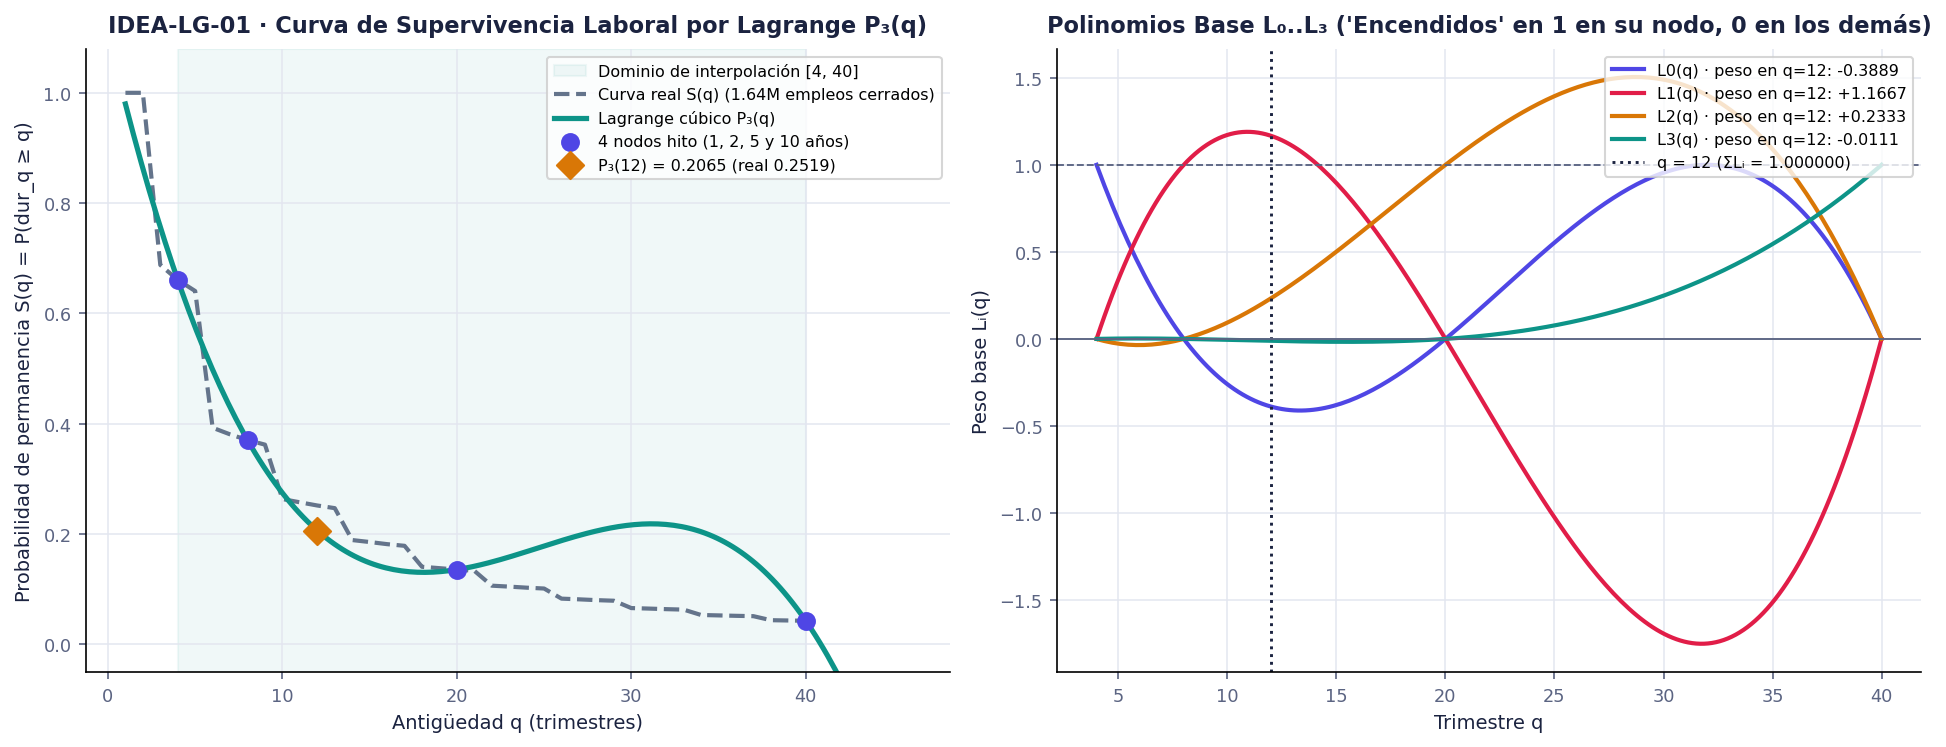

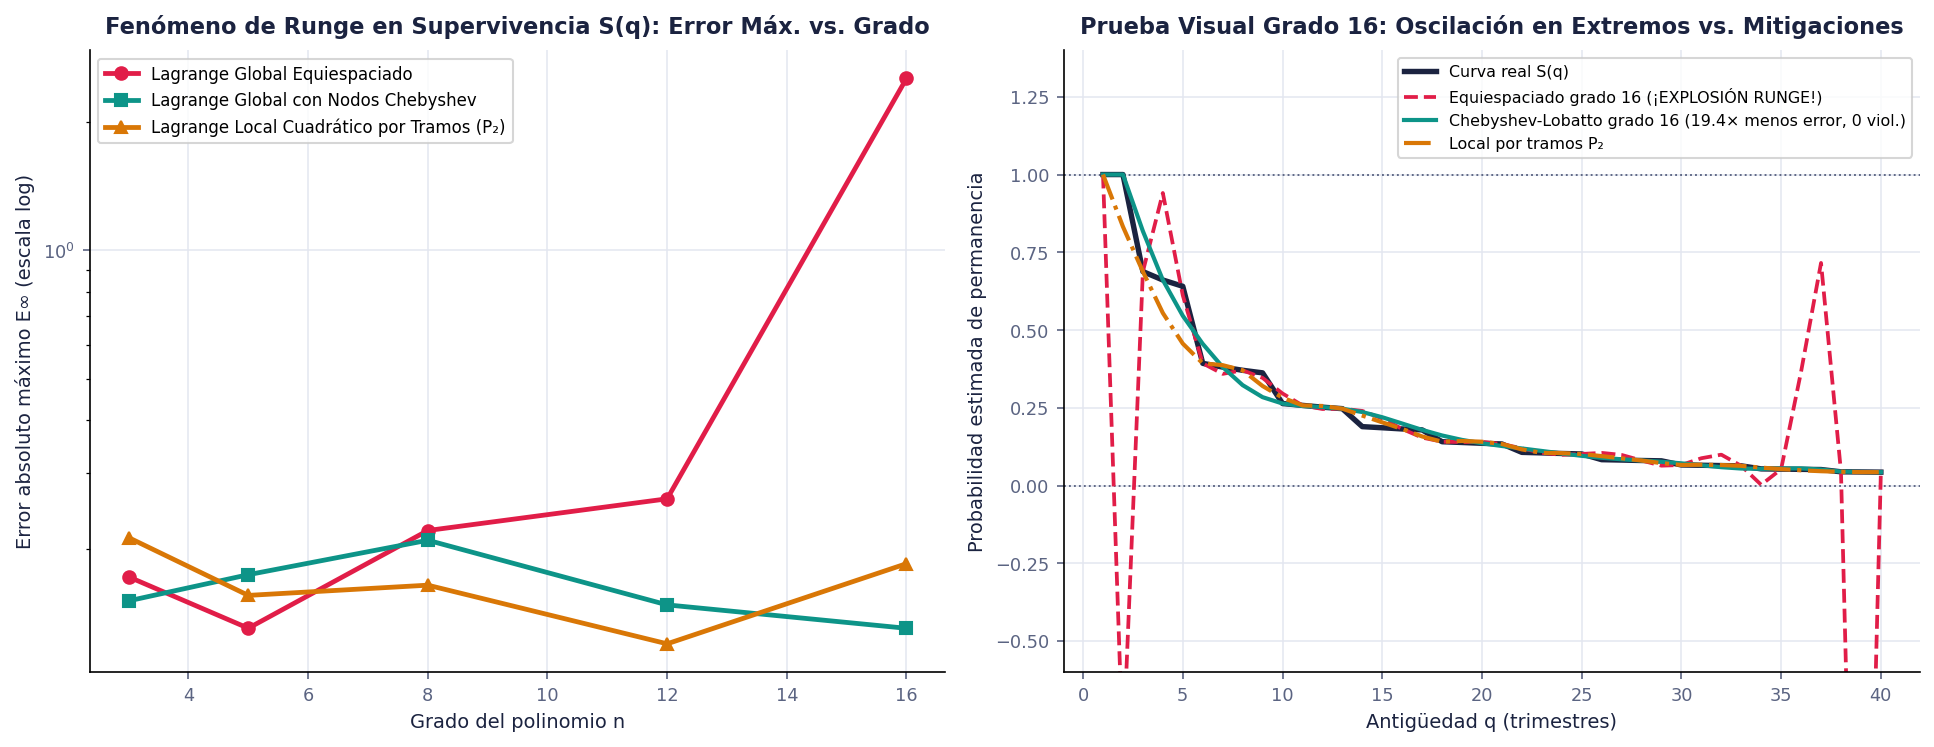

In [4]:
display(Image(filename=str(fdir / "nm07_lg01_survival_milestones_and_weights.png")))
display(Image(filename=str(fdir / "nm08_lg01_runge_phenomenon_vs_chebyshev.png")))

## 3. `IDEA-LG-02` — Interpolación Directa e Inversa Monótona de Varianza Acumulada PCA (`4.1_PCA_completo` en vivo)

**Propósito:** Recalcular en vivo en `float64` la curva de varianza acumulada PCA (`n = 50,000`, `random_state = 42`) directamente desde `data/03_processed/` (replicando exactamente `4.1_PCA_completo.ipynb`), interpolar componentes intermedios desde nodos dispersos ($k \in \{1, 3, 5, 8\} \to \{2, 4, 6, 7\}$) y resolver la **interpolación inversa de Lagrange** $k(V^*)$ para umbrales $V^* \in \{80\%, 85\%, 90\%, 95\%\}$ en Versión A vs. Versión B—demostrando en vivo la **salvaguarda de nodos distintos (`MR-04`)** cuando Versión A alcanza su meseta colineal de rango 9 $V(9) = V(10) = 1.0$.

In [5]:
pca_ref = pd.read_csv(tdir / "lg02_pca_50k_reference.csv")
display(pca_ref)

print("\nPrecisión de interpolación directa P3 (nodos retenidos k = 2, 4, 6, 7):")
display(pd.read_csv(tdir / "lg02_pca_forward_P3_eval.csv"))

print("\nDimensionalidad efectiva k(V*) mediante interpolación inversa monótona:")
display(pd.read_csv(tdir / "lg02_pca_inverse_effective_dim.csv"))

# Verificación en vivo de la salvaguarda MR-04 sobre la meseta de Versión A
try:
    inverse_lagrange_eval(pca_ref["k_components"].values, pca_ref["cum_var_version_a"].values, [0.90])
except ValueError as err:
    print(f"\n[PASS] Salvaguarda MR-04 de nodos distintos activada en meseta de Versión A: {err}")

,k_components,cum_var_version_a,cum_var_version_b,marginal_var_version_a,marginal_var_version_b
0,1,0.329105,0.396820,3.291052e-01,0.396820
1,2,0.553603,0.658927,2.244980e-01,0.262107
2,3,0.765877,0.805850,2.122741e-01,0.146922
3,4,0.877604,0.890892,1.117270e-01,0.085042
4,5,0.940656,0.953598,6.305202e-02,0.062706
5,6,0.994310,0.992809,5.365376e-02,0.039211
6,7,0.998870,0.998265,4.560318e-03,0.005456
7,8,0.999954,0.999568,1.083855e-03,0.001303
8,9,1.000000,0.999945,4.571288e-05,0.000377
9,10,1.000000,1.000000,6.740524e-18,0.000055



Precisión de interpolación directa P3 (nodos retenidos k = 2, 4, 6, 7):


,version,k_eval,true_cum_var,P3_pred,abs_err,sum_Li
0,Version A (con_outliers),2,0.553603,0.588479,0.034876,1.0
1,Version A (con_outliers),4,0.877604,0.877777,0.000173,1.0
2,Version A (con_outliers),6,0.994310,0.970994,0.023316,1.0
3,Version A (con_outliers),7,0.998870,0.985267,0.013603,1.0
4,Version B (sin_outliers),2,0.658927,0.642974,0.015954,1.0
5,Version B (sin_outliers),4,0.890892,0.903405,0.012513,1.0
6,Version B (sin_outliers),6,0.992809,0.974384,0.018424,1.0
7,Version B (sin_outliers),7,0.998265,0.983722,0.014543,1.0



Dimensionalidad efectiva k(V*) mediante interpolación inversa monótona:


,version,target_variance_V,k_est_local_P2,k_est_global_P5,k_ceil_recommended,actual_cum_var_at_ceil,meets_target,is_extrapolation
0,Version A (con_outliers),0.80,3.200725,3.207950,4,0.877604,True,False
1,Version A (con_outliers),0.85,3.661129,3.661313,4,0.877604,True,False
2,Version A (con_outliers),0.90,4.333519,4.321707,5,0.940656,True,False
3,Version A (con_outliers),0.95,5.164292,5.169342,6,0.994310,True,False
4,Version B (sin_outliers),0.80,2.942566,2.936766,3,0.805850,True,False
5,Version B (sin_outliers),0.85,3.467974,3.498887,4,0.890892,True,False
6,Version B (sin_outliers),0.90,4.099477,4.121194,5,0.953598,True,False
7,Version B (sin_outliers),0.95,4.922681,4.927779,5,0.953598,True,False



[PASS] Salvaguarda MR-04 de nodos distintos activada en meseta de Versión A: Interpolation nodes x_i must be strictly distinct (min gap = 0.000e+00 < 1.0e-12).


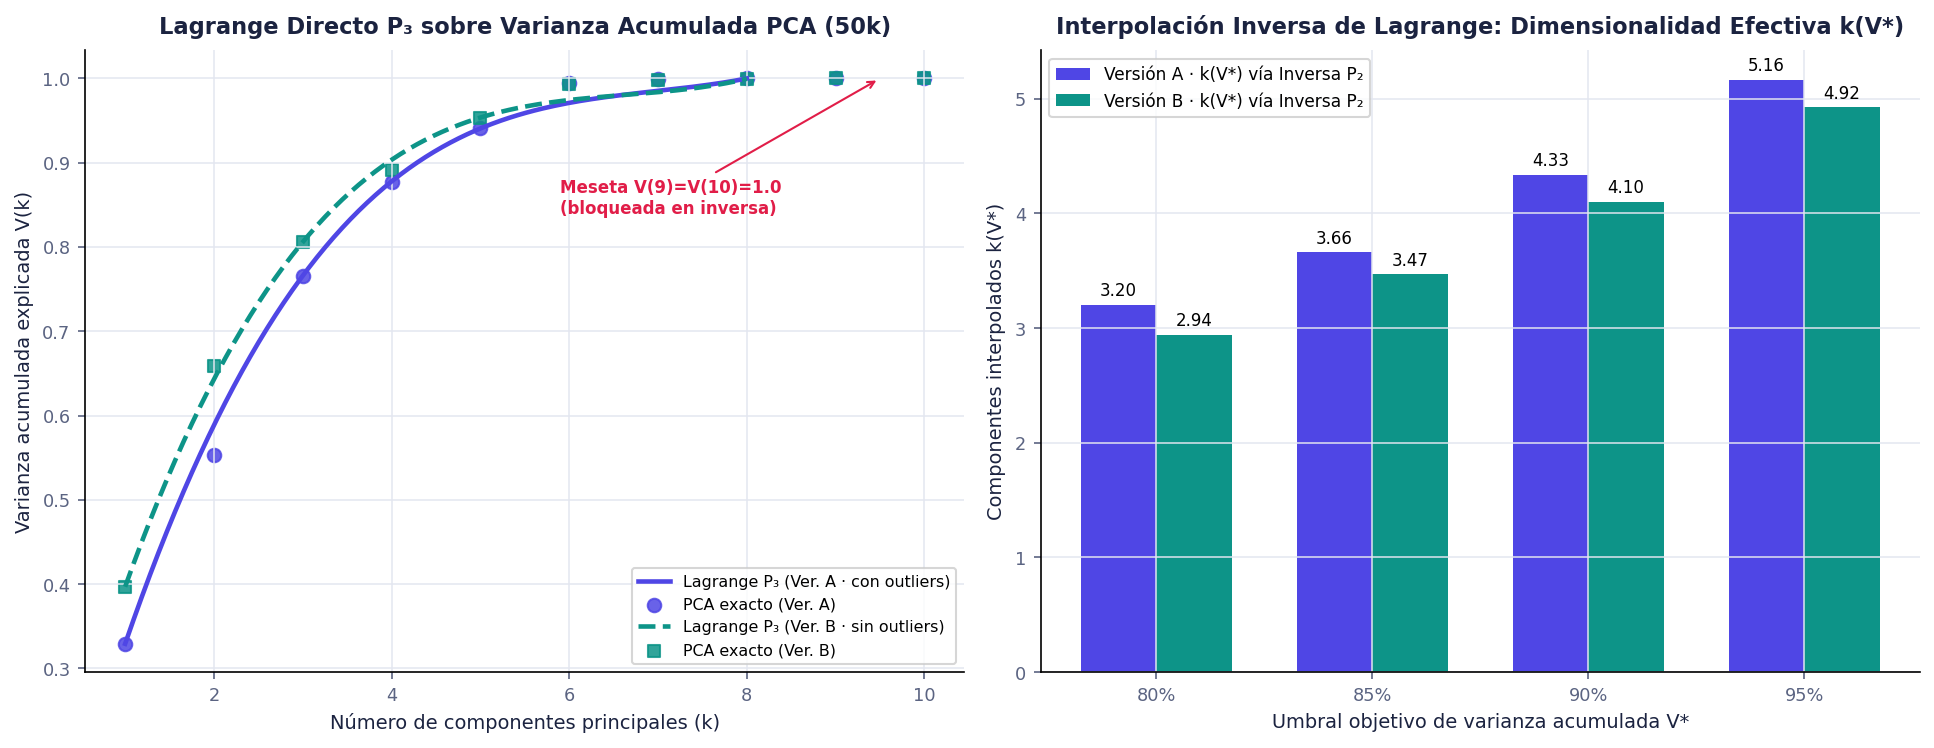

In [6]:
display(Image(filename=str(fdir / "nm09_lg02_pca_forward_and_inverse_lagrange.png")))